## Text Analysis with Score (Points) Target
By Chris Liu

In [45]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# data_file = Path('datasets/winemag-data-130k-v2.csv')
# reviews = pd.read_csv(data_file)
# reviews.head()


df = pd.read_csv("datasets/winemag-data-130k-v2.csv")

# Remove the CSV export index, then remove duplicate reviews
df = (
    df.drop(columns="Unnamed: 0")
      .drop_duplicates(subset=["title", "description"])
      .reset_index(drop=True)
)

# Wine Enthusiast score bands: use this ordered category as the classification target.
SCORE_BINS = [79, 82, 86, 89, 93, 97, 100]
SCORE_LABELS = ["Acceptable (80–82)", "Good (83–86)", "Very Good (87–89)",
                "Excellent (90–93)", "Superb (94–97)", "Classic (98–100)"]
df["score_category"] = pd.cut(
    df["points"], bins=SCORE_BINS, labels=SCORE_LABELS, include_lowest=True
)
reviews = df

print(f"Reviews remaining: {df.shape[0]:,}")

Reviews remaining: 119,988


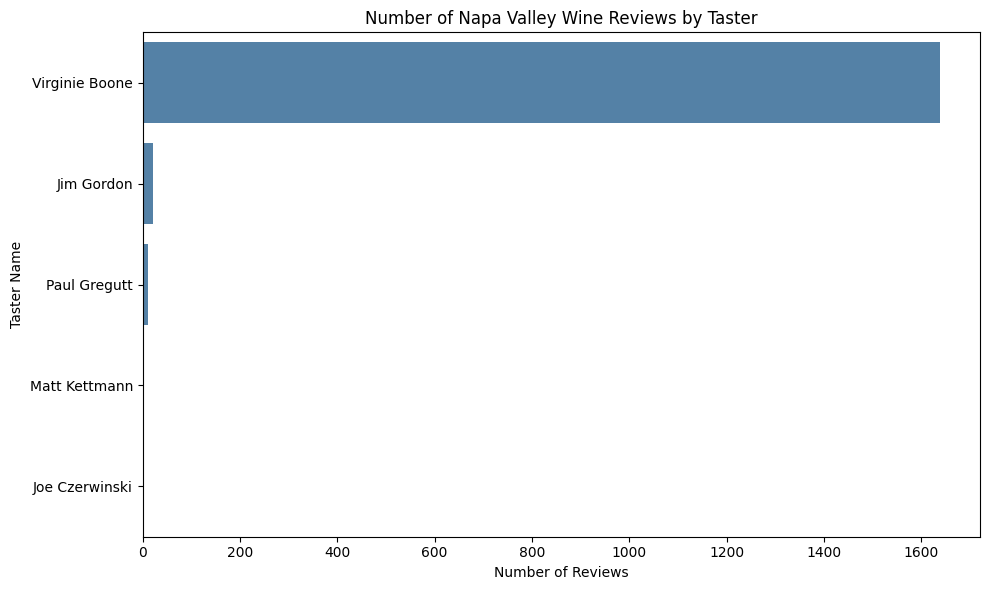

In [46]:
# Keep Napa Valley wines and non-missing tasters
napa = df.loc[
    (df["region_1"] == "Napa Valley") & df["taster_name"].notna()
].copy()

# Count reviews by taster
taster_counts = napa["taster_name"].value_counts()

# Bar chart (best visualization for categorical taster names)
plt.figure(figsize=(10, 6))
sns.barplot(x=taster_counts.values, y=taster_counts.index, color="steelblue")
plt.title("Number of Napa Valley Wine Reviews by Taster")
plt.xlabel("Number of Reviews")
plt.ylabel("Taster Name")
plt.tight_layout()
plt.show()

In [47]:
# Count reviews in each specific wine region.
region_counts = reviews['region_1'].dropna().value_counts()

most_reviewed_region = region_counts.index[0]
most_reviewed_count = region_counts.iloc[0]

print(f'Region with the most reviews: {most_reviewed_region}')
print(f'Number of reviews: {most_reviewed_count:,}')

region_counts.head(10)

Region with the most reviews: Napa Valley
Number of reviews: 4,174


region_1
Napa Valley             4174
Columbia Valley (WA)    3795
Russian River Valley    2862
California              2468
Paso Robles             2155
Mendoza                 2152
Willamette Valley       2111
Alsace                  1973
Champagne               1498
Barolo                  1493
Name: count, dtype: int64

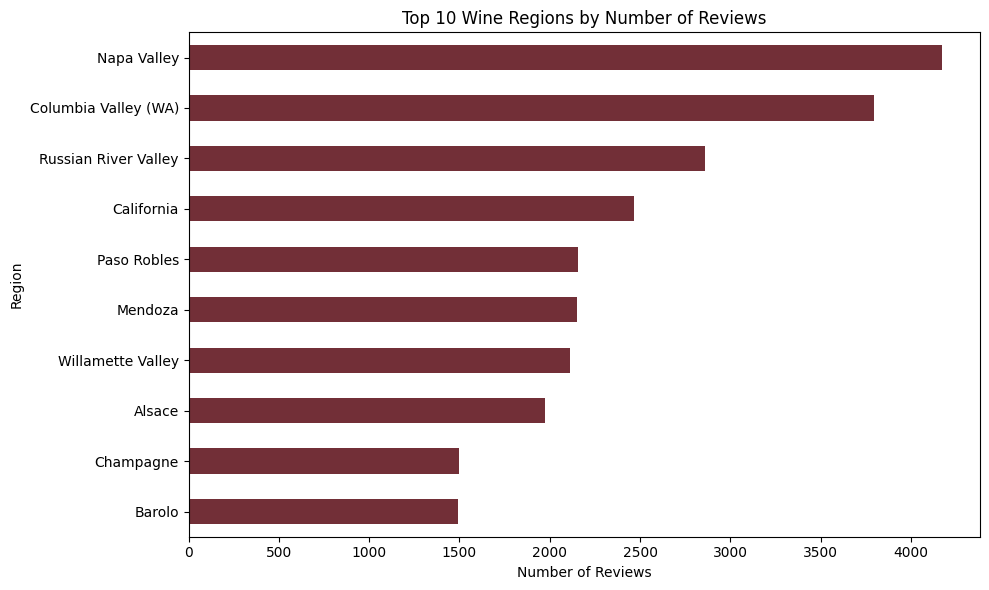

In [48]:
# Visualize the ten regions with the most reviews.
top_regions = region_counts.head(10).sort_values()

ax = top_regions.plot(kind='barh', figsize=(10, 6), color='#722F37')
ax.set_title('Top 10 Wine Regions by Number of Reviews')
ax.set_xlabel('Number of Reviews')
ax.set_ylabel('Region')
plt.tight_layout()
plt.show()

### Filtering and target variable

- Focus on **Napa Valley** (`region_1`).
- target variable: `points`

In [49]:
# Keep only Napa Valley reviews for score EDA.
napa_reviews = reviews.loc[reviews['region_1'].eq('Napa Valley')].copy()

score_summary = napa_reviews['points'].describe().to_frame(name='Napa Valley scores')
score_summary.loc['high_score_rate (90+)'] = (napa_reviews['points'] >= 90).mean()

display(score_summary.round(2))
display(napa_reviews['score_category'].value_counts(sort=False).rename('review_count').to_frame())
print(f"Napa Valley reviews: {len(napa_reviews):,}")
print(f"Share rated 90 or higher: {(napa_reviews['points'] >= 90).mean():.1%}")

,Napa Valley scores
count,4174.00
mean,89.05
std,3.25
min,80.00
25%,87.00
50%,89.00
75%,91.00
max,100.00
high_score_rate (90+),0.49


,review_count
score_category,
Acceptable (80–82),76
Good (83–86),878
Very Good (87–89),1166
Excellent (90–93),1698
Superb (94–97),348
Classic (98–100),8


Napa Valley reviews: 4,174
Share rated 90 or higher: 49.2%


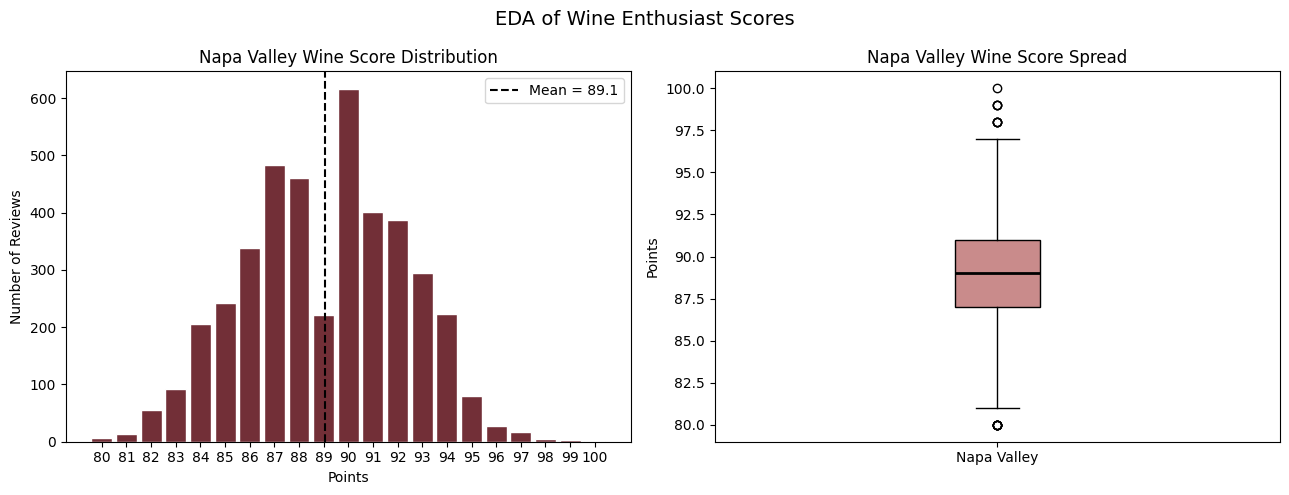

In [50]:
# Score distribution and spread for Napa Valley wines.
scores = napa_reviews['points']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(scores, bins=range(scores.min(), scores.max() + 2),
             align='left', rwidth=0.85, color='#722F37', edgecolor='white')
axes[0].axvline(scores.mean(), color='black', linestyle='--',
                label=f'Mean = {scores.mean():.1f}')
axes[0].set_title('Napa Valley Wine Score Distribution')
axes[0].set_xlabel('Points')
axes[0].set_ylabel('Number of Reviews')
axes[0].set_xticks(range(scores.min(), scores.max() + 1))
axes[0].legend()

axes[1].boxplot(scores, patch_artist=True,
                boxprops=dict(facecolor='#C98B8B'),
                medianprops=dict(color='black', linewidth=2))
axes[1].set_title('Napa Valley Wine Score Spread')
axes[1].set_ylabel('Points')
axes[1].set_xticks([1], ['Napa Valley'])

fig.suptitle('EDA of Wine Enthusiast Scores', fontsize=14)
plt.tight_layout()
plt.show()

`points` is our target variable. We begin with Napa Valley reviews and use the vintage embedded in `title` as a proxy for the order in which review batches arrive. Models use **review text only**; vintage is used only to define the chronological train/test splits.

Chronological modeling sample (Napa, 2004–2015): 3,847 unique reviews


,mean_score,median_score,std_score,review_count
vintage,,,,
2004,88.39,89.0,3.55,97
2005,88.69,88.0,3.49,221
2006,88.63,87.0,3.87,239
2007,88.92,88.0,3.64,323
2008,89.27,89.0,3.51,342
2009,89.30,90.0,3.43,443
2010,88.79,89.0,3.04,419
2011,88.06,88.0,3.10,319
2012,88.90,90.0,3.04,544


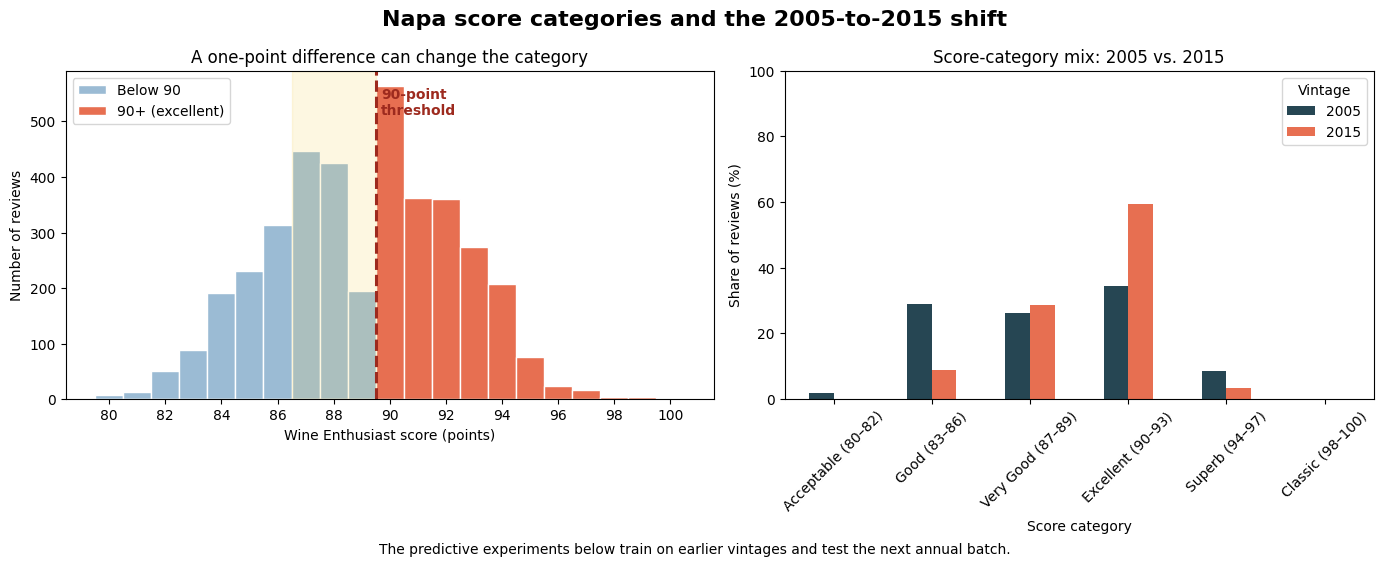

In [51]:
import numpy as np
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error
from sklearn.pipeline import make_pipeline
import warnings

# Vintage is not a supplied column, so extract a four-digit year from the title.
napa_time = napa_reviews[['title', 'description', 'points', 'score_category']].copy()
napa_time['vintage'] = pd.to_numeric(
    napa_time['title'].str.extract(r'\b((?:19|20)\d{2})\b', expand=False),
    errors='coerce'
)
# Retain reviews usable for text modeling and remove exact title/review repeats.
napa_time = (napa_time.dropna(subset=['vintage', 'description', 'points', 'score_category'])
                       .drop_duplicates(subset=['title', 'description'])
                       .sort_values('vintage')
                       .reset_index(drop=True))
napa_time['vintage'] = napa_time['vintage'].astype(int)

# Agreed Team Paso Robles scope: Napa Valley reviews from 2004 through 2015.
SCOPE_YEARS = list(range(2004, 2016))
napa_time = napa_time.loc[napa_time['vintage'].isin(SCOPE_YEARS)].copy()

yearly_scores = napa_time.groupby('vintage')['points'].agg(
    mean_score='mean', median_score='median', std_score='std', review_count='size'
)
print(f'Chronological modeling sample (Napa, 2004–2015): {len(napa_time):,} unique reviews')
display(yearly_scores.round(2))

# Supporting comparison requested by the team: how did the 2005 and 2015 batches differ?
score_mix_2005_2015 = (
    pd.crosstab(napa_time['vintage'], napa_time['score_category'], normalize='index')
    .reindex(index=[2005, 2015], columns=SCORE_LABELS, fill_value=0)
    .mul(100)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1.1, 1]})

# Left: show the full points distribution.
bins = range(int(napa_time['points'].min()), int(napa_time['points'].max()) + 2)
axes[0].hist(napa_time.loc[napa_time['points'] < 90, 'points'], bins=bins, align='left',
             color='#9BBBD4', edgecolor='white', label='Below 90')
axes[0].hist(napa_time.loc[napa_time['points'] >= 90, 'points'], bins=bins, align='left',
             color='#E76F51', edgecolor='white', label='90+ (excellent)')
axes[0].axvline(89.5, color='#9D2A1E', linewidth=2.2, linestyle='--')
axes[0].axvspan(86.5, 89.5, color='#F4D35E', alpha=.18)
axes[0].text(89.7, axes[0].get_ylim()[1] * .95, '90-point\nthreshold', color='#9D2A1E',
             weight='bold', va='top')
axes[0].set(title='A one-point difference can change the category',
            xlabel='Wine Enthusiast score (points)', ylabel='Number of reviews')
axes[0].set_xticks(range(80, 101, 2))
axes[0].legend(loc='upper left')

# Right: compare the category mix in the first and final years of our scope.
score_mix_2005_2015.T.plot(kind='bar', ax=axes[1], color=['#264653', '#E76F51'])
axes[1].set(title='Score-category mix: 2005 vs. 2015', xlabel='Score category',
            ylabel='Share of reviews (%)', ylim=(0, 100))
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Vintage')

fig.suptitle('Napa score categories and the 2005-to-2015 shift', fontsize=16, weight='bold')
fig.text(.5, -.01, 'The predictive experiments below train on earlier vintages and test the next annual batch.',
         ha='center', fontsize=10)
plt.tight_layout()
plt.show()

### Chronological training and evaluation

We treat each vintage as an annual incoming batch. The experiment starts with 2004–2006 and tests every later year through 2015. For every test year, we compare a **fixed** model trained only on 2004–2006 with an **expanding** model retrained on all prior vintages.

The models predict the ordered Wine Enthusiast score category derived from `points` (Acceptable through Classic). We report **accuracy** and **multiclass macro F1** for every model.

In [52]:
INITIAL_TRAIN_END = 2006
TEST_YEARS = list(range(INITIAL_TRAIN_END + 1, 2016))

def make_classifier():
    return make_pipeline(
        TfidfVectorizer(stop_words='english', min_df=2, ngram_range=(1, 2),
                        max_features=25_000, sublinear_tf=True),
        LogisticRegression(max_iter=2_000, class_weight='balanced', C=1.0, random_state=4401)
    )

model_specs = [
    ('Most-frequent-category baseline', DummyClassifier(strategy='most_frequent')),
    ('TF-IDF + logistic regression', make_classifier()),
]

model_rows = []
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=RuntimeWarning, module='sklearn')
    for test_year in TEST_YEARS:
        test = napa_time[napa_time['vintage'] == test_year]
        training_sets = {
            'Fixed: train 2004–2006': napa_time[napa_time['vintage'] <= INITIAL_TRAIN_END],
            'Expanding: all prior vintages': napa_time[napa_time['vintage'] < test_year],
        }
        for training_strategy, train in training_sets.items():
            for model_name, model in model_specs:
                model.fit(train['description'], train['score_category'])
                predicted_categories = model.predict(test['description'])
                model_rows.append({
                    'test_vintage': test_year, 'training_strategy': training_strategy,
                    'model': model_name,
                    'train_n': len(train), 'test_n': len(test),
                    'Accuracy': accuracy_score(test['score_category'], predicted_categories),
                    'Macro F1': f1_score(
                        test['score_category'], predicted_categories, average='macro', zero_division=0
                    )
                })

chronological_results = pd.DataFrame(model_rows)
display(chronological_results.round(3))
print('Mean performance across chronological next-vintage tests:')
display(chronological_results.groupby(['training_strategy', 'model'])[['Accuracy', 'Macro F1']].mean().round(3))

,test_vintage,training_strategy,model,train_n,test_n,Accuracy,Macro F1
0,2007,Fixed: train 2004–2006,Most-frequent-category baseline,557,323,0.337,0.084
1,2007,Fixed: train 2004–2006,TF-IDF + logistic regression,557,323,0.477,0.346
2,2007,Expanding: all prior vintages,Most-frequent-category baseline,557,323,0.337,0.084
3,2007,Expanding: all prior vintages,TF-IDF + logistic regression,557,323,0.477,0.346
4,2008,Fixed: train 2004–2006,Most-frequent-category baseline,557,342,0.348,0.086
5,2008,Fixed: train 2004–2006,TF-IDF + logistic regression,557,342,0.482,0.364
6,2008,Expanding: all prior vintages,Most-frequent-category baseline,880,342,0.348,0.086
7,2008,Expanding: all prior vintages,TF-IDF + logistic regression,880,342,0.529,0.405
8,2009,Fixed: train 2004–2006,Most-frequent-category baseline,557,443,0.388,0.093
9,2009,Fixed: train 2004–2006,TF-IDF + logistic regression,557,443,0.479,0.289


Mean performance across chronological next-vintage tests:


Accuracy  \
training_strategy             model                                       
Expanding: all prior vintages Most-frequent-category baseline     0.427   
                              TF-IDF + logistic regression        0.518   
Fixed: train 2004–2006        Most-frequent-category baseline     0.427   
                              TF-IDF + logistic regression        0.417   

                                                               Macro F1  
training_strategy             model                                      
Expanding: all prior vintages Most-frequent-category baseline     0.110  
                              TF-IDF + logistic regression        0.361  
Fixed: train 2004–2006        Most-frequent-category baseline     0.110  
                              TF-IDF + logistic regression        0.299

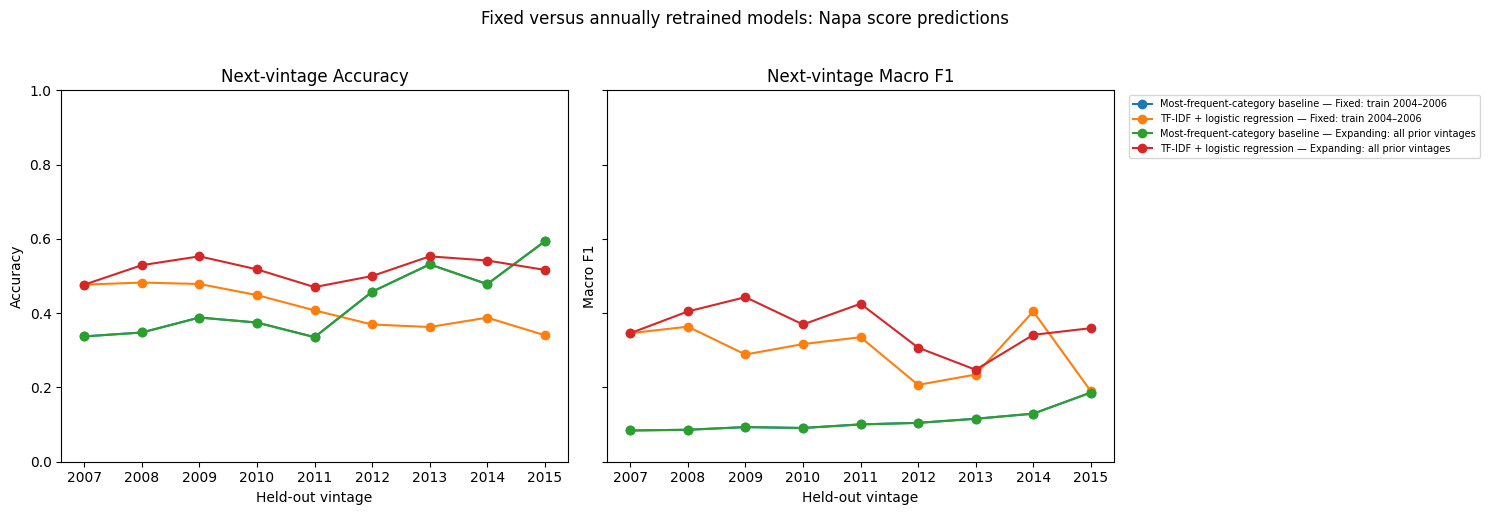

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True, sharey=True)
for ax, metric in zip(axes, ['Accuracy', 'Macro F1']):
    for (strategy, model_name), group in chronological_results.groupby(['training_strategy', 'model'], sort=False):
        ax.plot(group['test_vintage'], group[metric], marker='o', label=f'{model_name} — {strategy}')
    ax.set(title=f'Next-vintage {metric}', xlabel='Held-out vintage', ylabel=metric, ylim=(0, 1))
axes[1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left')
fig.suptitle('Fixed versus annually retrained models: Napa score predictions', y=1.02)
plt.tight_layout()
plt.show()

### Chronological numeric-score regression

This companion experiment predicts the original numeric `points` score. We use the same fixed-versus-expanding annual-batch design as above. **MAE** is the average absolute number of score points by which a prediction differs from the observed score; lower is better.

In [54]:
def make_score_regressor():
    return make_pipeline(
        TfidfVectorizer(stop_words='english', min_df=2, ngram_range=(1, 2),
                        max_features=25_000, sublinear_tf=True),
        Ridge(alpha=10.0, solver='lsqr', random_state=4401)
    )

regression_specs = [
    ('Historical-mean-points baseline', DummyRegressor(strategy='mean')),
    ('TF-IDF + Ridge regression', make_score_regressor()),
]

regression_rows = []
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', category=RuntimeWarning, module='sklearn')
    for test_year in TEST_YEARS:
        test = napa_time[napa_time['vintage'] == test_year]
        training_sets = {
            'Fixed: train 2004–2006': napa_time[napa_time['vintage'] <= INITIAL_TRAIN_END],
            'Expanding: all prior vintages': napa_time[napa_time['vintage'] < test_year],
        }
        for training_strategy, train in training_sets.items():
            for model_name, model in regression_specs:
                model.fit(train['description'], train['points'])
                predicted_points = model.predict(test['description'])
                regression_rows.append({
                    'test_vintage': test_year, 'training_strategy': training_strategy,
                    'model': model_name, 'train_n': len(train), 'test_n': len(test),
                    'MAE (points)': mean_absolute_error(test['points'], predicted_points),
                })

regression_results = pd.DataFrame(regression_rows)
display(regression_results.round(3))
print('Mean MAE across chronological next-vintage tests:')
display(regression_results.groupby(['training_strategy', 'model'])[['MAE (points)']].mean().round(3))

,test_vintage,training_strategy,model,train_n,test_n,MAE (points)
0,2007,Fixed: train 2004–2006,Historical-mean-points baseline,557,323,3.093
1,2007,Fixed: train 2004–2006,TF-IDF + Ridge regression,557,323,2.629
2,2007,Expanding: all prior vintages,Historical-mean-points baseline,557,323,3.093
3,2007,Expanding: all prior vintages,TF-IDF + Ridge regression,557,323,2.629
4,2008,Fixed: train 2004–2006,Historical-mean-points baseline,557,342,2.999
5,2008,Fixed: train 2004–2006,TF-IDF + Ridge regression,557,342,2.551
6,2008,Expanding: all prior vintages,Historical-mean-points baseline,880,342,2.992
7,2008,Expanding: all prior vintages,TF-IDF + Ridge regression,880,342,2.404
8,2009,Fixed: train 2004–2006,Historical-mean-points baseline,557,443,2.950
9,2009,Fixed: train 2004–2006,TF-IDF + Ridge regression,557,443,2.538


Mean MAE across chronological next-vintage tests:


MAE (points)
training_strategy             model                                        
Expanding: all prior vintages Historical-mean-points baseline         2.626
                              TF-IDF + Ridge regression               2.144
Fixed: train 2004–2006        Historical-mean-points baseline         2.660
                              TF-IDF + Ridge regression               2.389

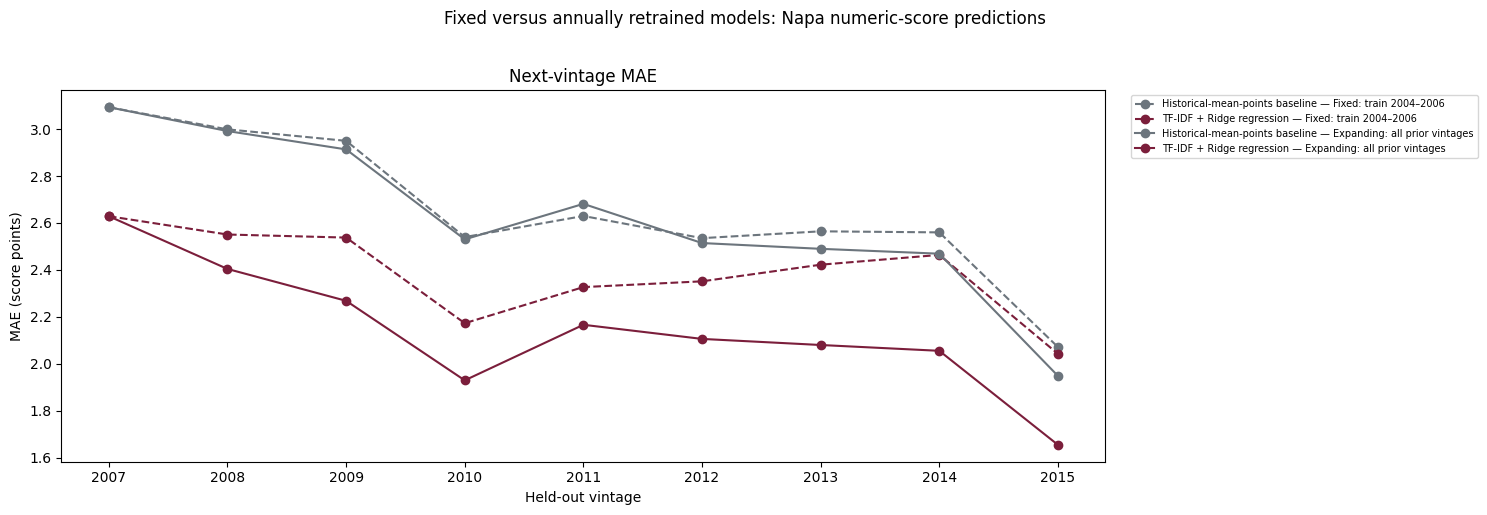

In [55]:
model_colors = {
    'Historical-mean-points baseline': '#6C757D',
    'TF-IDF + Ridge regression': '#7B1E3B',
}
strategy_styles = {
    'Fixed: train 2004–2006': '--',
    'Expanding: all prior vintages': '-',
}

fig, ax = plt.subplots(figsize=(15, 5))
for (model_name, strategy), group in regression_results.groupby(['model', 'training_strategy'], sort=False):
    group = group.sort_values('test_vintage')
    ax.plot(
        group['test_vintage'], group['MAE (points)'], marker='o',
        color=model_colors[model_name], linestyle=strategy_styles[strategy],
        label=f'{model_name} — {strategy}'
    )

ax.set(title='Next-vintage MAE', xlabel='Held-out vintage', ylabel='MAE (score points)')
ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left')
fig.suptitle('Fixed versus annually retrained models: Napa numeric-score predictions', y=1.02)
plt.tight_layout()
plt.show()

### Review-language evolution

Compare average TF-IDF usage in the 2005 and 2015 Napa batches to identify language that changed over time. These are associations, not causal claims.

In [56]:
# Describe the requested 2005-versus-2015 language shift without using score labels.
early_reviews = napa_time.query('vintage == 2005')
late_reviews = napa_time.query('vintage == 2015')
shift_vectorizer = TfidfVectorizer(stop_words='english', min_df=5, max_features=10_000, sublinear_tf=True)
X_shift = shift_vectorizer.fit_transform(pd.concat([early_reviews['description'], late_reviews['description']]))
early_mean = np.asarray(X_shift[:len(early_reviews)].mean(axis=0)).ravel()
late_mean = np.asarray(X_shift[len(early_reviews):].mean(axis=0)).ravel()
language_shift = pd.DataFrame({
    'term': shift_vectorizer.get_feature_names_out(),
    'mean_tfidf_2005': early_mean, 'mean_tfidf_2015': late_mean
})
language_shift['difference_2015_minus_2005'] = language_shift['mean_tfidf_2015'] - language_shift['mean_tfidf_2005']
more_late = language_shift.nlargest(15, 'difference_2015_minus_2005').assign(period='more characteristic of 2015')
more_early = language_shift.nsmallest(15, 'difference_2015_minus_2005').assign(period='more characteristic of 2005')
display(pd.concat([more_late, more_early], ignore_index=True).round(3))

,term,mean_tfidf_2005,mean_tfidf_2015,difference_2015_minus_2005,period
0,bodied,0.006,0.074,0.068,more characteristic of 2015
1,white,0.002,0.067,0.065,more characteristic of 2015
2,lemon,0.001,0.066,0.065,more characteristic of 2015
3,apple,0.000,0.056,0.056,more characteristic of 2015
4,peach,0.004,0.058,0.055,more characteristic of 2015
5,pear,0.004,0.055,0.050,more characteristic of 2015
6,palate,0.011,0.059,0.049,more characteristic of 2015
7,medium,0.000,0.044,0.044,more characteristic of 2015
8,floral,0.000,0.040,0.040,more characteristic of 2015
9,vanilla,0.009,0.048,0.039,more characteristic of 2015
